In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

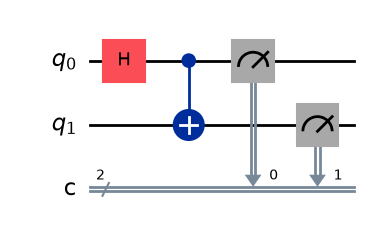

In [2]:
# Part A: Correlated outcomes
qc_a = QuantumCircuit(2, 2)

qc_a.h(0)
qc_a.cx(0, 1)

# Measure both qubits
qc_a.measure([0, 1], [0, 1])

# Display the circuit
qc_a.draw('mpl')

In [3]:
print("Part A - Prediction")
print("00: approximately 50%")
print("11: approximately 50%")
print("01: approximately 0%")
print("10: approximately 0%")

Part A - Prediction
00: approximately 50%
11: approximately 50%
01: approximately 0%
10: approximately 0%


In [4]:
simulator = AerSimulator()

job_a = simulator.run(qc_a, shots=100)
result_a = job_a.result()

counts_a = result_a.get_counts()

print("Part A measurement results:", counts_a)
print("Total shots:", sum(counts_a.values()))

Part A measurement results: {'00': 50, '11': 50}
Total shots: 100


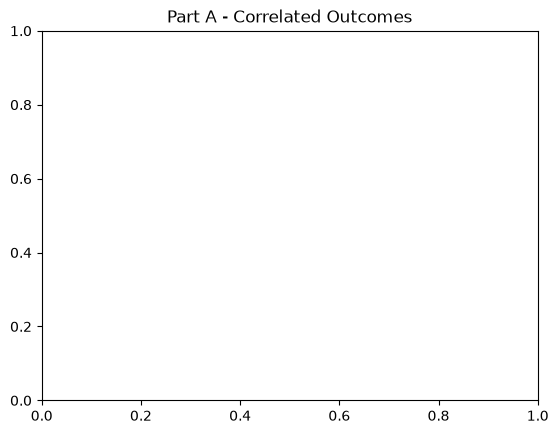

In [5]:
plot_histogram(counts_a)
plt.title("Part A - Correlated Outcomes")
plt.show()

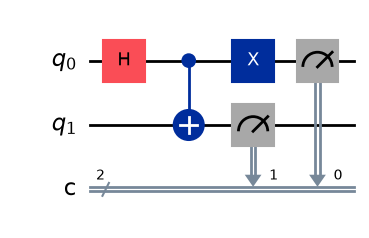

In [6]:
# Part B: Opposite outcomes
qc_b = QuantumCircuit(2, 2)

qc_b.h(0)
qc_b.cx(0, 1)

# Add one gate to switch the correlation
qc_b.x(0)

# Measure both qubits
qc_b.measure([0, 1], [0, 1])

# Display the circuit
qc_b.draw('mpl')

In [7]:
print("Part B - Prediction")
print("01: approximately 50%")
print("10: approximately 50%")
print("00: approximately 0%")
print("11: approximately 0%")

Part B - Prediction
01: approximately 50%
10: approximately 50%
00: approximately 0%
11: approximately 0%


In [8]:
job_b = simulator.run(qc_b, shots=100)
result_b = job_b.result()

counts_b = result_b.get_counts()

print("Part B measurement results:", counts_b)
print("Total shots:", sum(counts_b.values()))

Part B measurement results: {'01': 48, '10': 52}
Total shots: 100


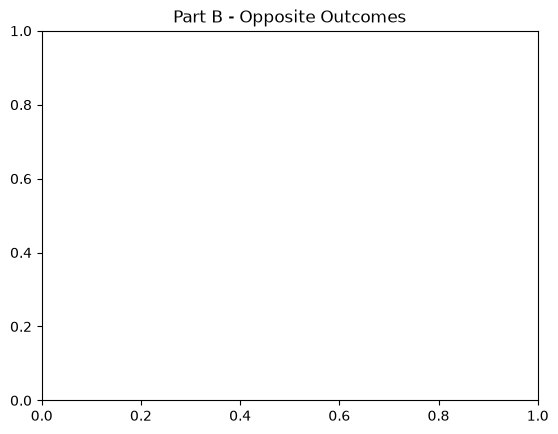

In [9]:
plot_histogram(counts_b)
plt.title("Part B - Opposite Outcomes")
plt.show()

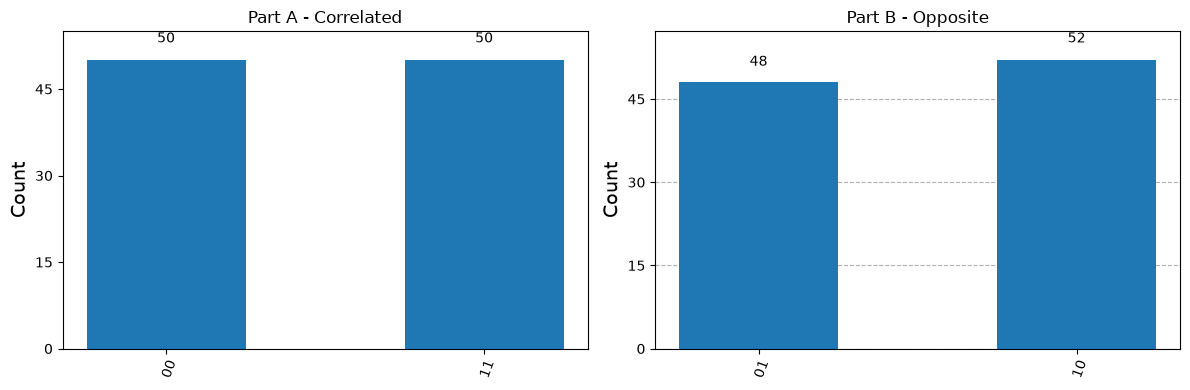

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

plot_histogram(counts_a, ax=axes[0])
axes[0].set_title("Part A - Correlated")

plot_histogram(counts_b, ax=axes[1])
axes[1].set_title("Part B - Opposite")

plt.tight_layout()
plt.show()

In [11]:
print("PART A - CORRELATED OUTCOMES")
for outcome in ['00', '01', '10', '11']:
    count = counts_a.get(outcome, 0)
    print(f"{outcome}: {count} shots ({count}%)")

print("\nPART B - OPPOSITE OUTCOMES")
for outcome in ['00', '01', '10', '11']:
    count = counts_b.get(outcome, 0)
    print(f"{outcome}: {count} shots ({count}%)")

PART A - CORRELATED OUTCOMES
00: 50 shots (50%)
01: 0 shots (0%)
10: 0 shots (0%)
11: 50 shots (50%)

PART B - OPPOSITE OUTCOMES
00: 0 shots (0%)
01: 48 shots (48%)
10: 52 shots (52%)
11: 0 shots (0%)
